# Autoregressive Text Generation on *Pride and Prejudice* with Simple RNN, Bidirectional RNN, LSTM and GRU

**Course:** Foundations of Generative AI (ICT4403) — Assignment 2

**Objective.** Build a word-level autoregressive language model that predicts the next word
$w_t$ from the previous $n$ words, $p(w_t \mid w_{t-n},\dots,w_{t-1})$, and generates text by
repeatedly sampling a word and feeding it back as input. Four recurrent architectures —
**Simple RNN, Bidirectional RNN, LSTM, GRU** — are trained under identical conditions and compared
quantitatively (loss, perplexity, accuracy, training time) and qualitatively (coherence, diversity,
contextual consistency, repetition) at several sampling temperatures.

All logic lives in the `textgen/` package; this notebook runs the complete pipeline end-to-end.

In [1]:
%matplotlib inline
import json, platform, torch, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown

from textgen.data import (prepare_data, dataset_statistics, detokenize, DATASET_PAGE, DATASET_URL)
from textgen.models import build_model, count_parameters, MODEL_SPECS
from textgen.generate import generate
from textgen.experiment import (CONFIG, SEEDS, TEMPERATURES, train_all, generate_all, plot_dataset,
                                plot_history, plot_comparison, plot_temperature, save_json,
                                write_samples_markdown)

torch.set_num_threads(8)
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 200)
RESULTS, PLOTS, MODELS = Path("results"), Path("results/plots"), Path("models")
RESULTS.mkdir(exist_ok=True); PLOTS.mkdir(parents=True, exist_ok=True)
print("Python", platform.python_version(), "| PyTorch", torch.__version__,
      "| device: cpu | threads:", torch.get_num_threads())
print(json.dumps(CONFIG, indent=1))

Python 3.14.5 | PyTorch 2.13.0+cpu | device: cpu | threads: 8
{
 "seq_len": 20,
 "min_freq": 2,
 "embed_dim": 128,
 "hidden_dim": 256,
 "num_layers": 1,
 "dropout": 0.3,
 "batch_size": 256,
 "lr": 0.002,
 "max_epochs": 20,
 "patience": 3,
 "clip": 5.0,
 "seed": 42
}


## 1. Dataset — characteristics

**Dataset:** *Pride and Prejudice* by Jane Austen (1813), Project Gutenberg eBook #1342.
Source: <https://www.gutenberg.org/ebooks/1342> (plain text: <https://www.gutenberg.org/cache/epub/1342/pg1342.txt>).

It is a public-domain English novel of 61 chapters: long, formal, early-19th-century prose with a lot of
dialogue, a small recurring cast (Elizabeth, Darcy, Jane, Bingley, Mr./Mrs. Bennet, Wickham, Lydia…),
and a rich but stable vocabulary — a good, self-contained corpus for a next-word model trained on a CPU.
The file is downloaded automatically if `data/pride_and_prejudice.txt` is missing.

In [2]:
data = prepare_data("data/pride_and_prejudice.txt", seq_len=CONFIG["seq_len"], min_freq=CONFIG["min_freq"])
stats = dataset_statistics(data)
stats_tbl = {k: v for k, v in stats.items() if k not in ("sentence_lengths",)}
save_json(stats_tbl, RESULTS / "dataset_stats.json")
display(pd.Series({k: (round(v, 4) if isinstance(v, float) else v) for k, v in stats_tbl.items()},
                  name="value").to_frame())
print("Raw text excerpt (after Gutenberg header removal):\n")
print(data["body"][:600])

,value
raw_characters,748167
novel_characters,694354
chapters,61
paragraphs,2369
sentences,5912
avg_sentence_length_tokens,22.5859
total_tokens_incl_punct,139440
word_tokens,122176
unique_words,6316
hapax_legomena,2362


Raw text excerpt (after Gutenberg header removal):

It is a truth universally acknowledged, that a single man in possession
of a good fortune must be in want of a wife.

However little known the feelings or views of such a man may be on his
first entering a neighbourhood, this truth is so well fixed in the minds
of the surrounding families, that he is considered as the rightful
property of some one or other of their daughters.

“My dear Mr. Bennet,” said his lady to him one day, “have you heard that
Netherfield Park is let at last?”

Mr. Bennet replied that he had not.

“But it is,” returned she; “for Mrs. Long has just been here, and she
told 


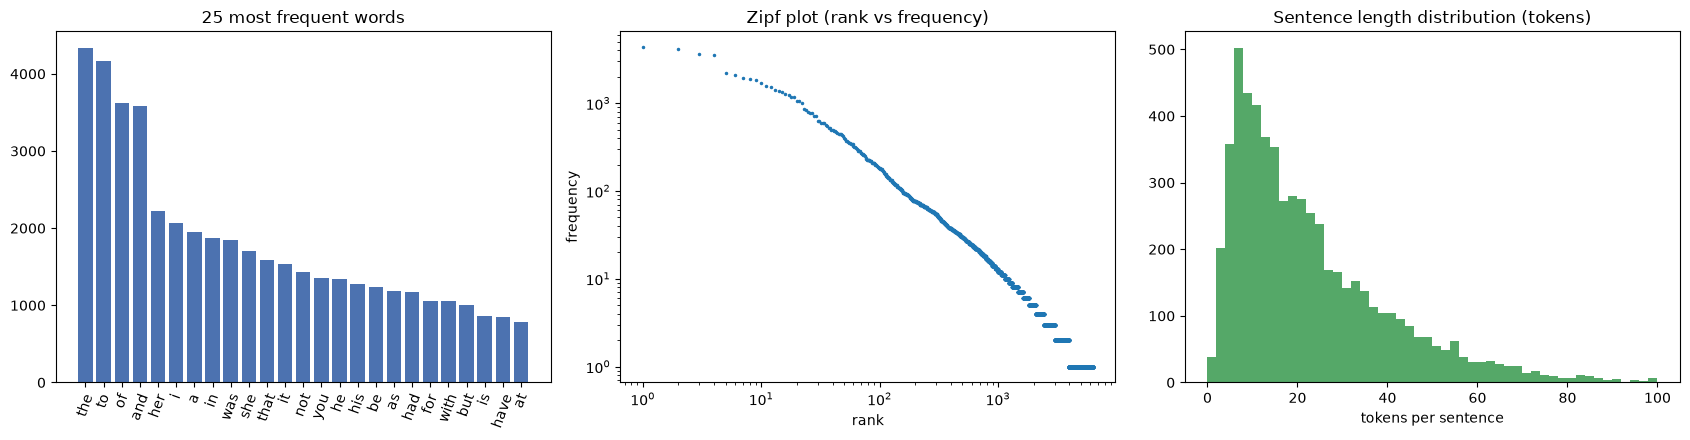

In [3]:
fig = plot_dataset(data, stats, PLOTS)
plt.show()

## 2. Pre-processing

1. **Strip boiler-plate:** keep only the novel (from *"It is a truth universally acknowledged"* to the
   last sentence); remove the Gutenberg licence, front matter, the printer's colophon and the
   multi-line `[Illustration: …]` captions (nested brackets handled).
2. **Normalise:** remove `CHAPTER …` headings and `_italic_` markers, convert curly quotes, split hyphenated
   words and dashes, lower-case, keep `mr/mrs/dr` without the full stop so `.` always marks a sentence end,
   collapse whitespace.
3. **Tokenise (word level):** words (with internal apostrophes, e.g. `don't`, `elizabeth's`) plus the
   punctuation tokens `. , ; : ! ?` so the model also learns sentence structure. Quotation marks are dropped.
4. **Split** the token stream *contiguously* into 80 % train / 10 % validation / 10 % test, so that
   overlapping windows never leak between splits.
5. **Vocabulary** built on the training split only; words occurring fewer than `min_freq = 2` times map
   to `<unk>`.

In [4]:
print("Cleaned text sample:\n", data["text"][:500], "\n")
print("First 40 tokens:", data["tokens"][:40], "\n")
v = data["vocab"]
print(f"Vocabulary size: {len(v)} (incl. <pad>, <unk>)")
print("Most frequent tokens:", v.counter.most_common(15))
print("<unk> rate:", {k: f"{r:.2%}" for k, r in stats["unk_rate"].items()})

Cleaned text sample:
 it is a truth universally acknowledged, that a single man in possession of a good fortune must be in want of a wife. however little known the feelings or views of such a man may be on his first entering a neighbourhood, this truth is so well fixed in the minds of the surrounding families, that he is considered as the rightful property of some one or other of their daughters. "my dear mr bennet," said his lady to him one day, "have you heard that netherfield park is let at last?" mr bennet replie 

First 40 tokens: ['it', 'is', 'a', 'truth', 'universally', 'acknowledged', ',', 'that', 'a', 'single', 'man', 'in', 'possession', 'of', 'a', 'good', 'fortune', 'must', 'be', 'in', 'want', 'of', 'a', 'wife', '.', 'however', 'little', 'known', 'the', 'feelings', 'or', 'views', 'of', 'such', 'a', 'man', 'may', 'be', 'on', 'his'] 

Vocabulary size: 3606 (incl. <pad>, <unk>)
Most frequent tokens: [(',', 7581), ('.', 3898), ('the', 3590), ('to', 3258), ('of', 3014), ('and', 29

## 3. Input–target sequences for autoregressive modelling

A sliding window with stride 1 turns the token stream $w_1 \dots w_N$ into training pairs

$$X_i = (w_i, \dots, w_{i+n-1}) \;\longrightarrow\; y_i = w_{i+n}, \qquad n = 20.$$

Each model therefore learns $p(w_{t} \mid w_{t-20:t-1})$. At generation time the predicted word is appended to the
context and the last 20 tokens are fed back in (sequential generation).

In [5]:
for split, (X, y) in data["splits"].items():
    print(f"{split:5s}: X {tuple(X.shape)}  y {tuple(y.shape)}")
X, y = data["splits"]["train"]
rows = [{"input (20 tokens)": " ".join(v.decode(X[i])), "target": v.itos[int(y[i])]} for i in range(0, 6)]
display(pd.DataFrame(rows))
print("Encoded example:", X[0].tolist(), "->", int(y[0]))

train: X (111532, 20)  y (111532,)
val  : X (13924, 20)  y (13924,)
test : X (13924, 20)  y (13924,)


,input (20 tokens),target
0,"it is a truth universally acknowledged , that a single man in possession of a good fortune must be in",want
1,"is a truth universally acknowledged , that a single man in possession of a good fortune must be in want",of
2,"a truth universally acknowledged , that a single man in possession of a good fortune must be in want of",a
3,"truth universally acknowledged , that a single man in possession of a good fortune must be in want of a",wife
4,"universally acknowledged , that a single man in possession of a good fortune must be in want of a wife",.
5,"acknowledged , that a single man in possession of a good fortune must be in want of a wife .",however


Encoded example: [16, 27, 9, 578, 2712, 822, 2, 15, 9, 983, 121, 10, 1251, 6, 9, 100, 365, 71, 20, 10] -> 357


## 4. Models

All four models share the same pipeline: `Embedding(V,128) → recurrent layer (hidden 256, 1 layer) →
Dropout(0.3) → Linear(→V)` and differ only in the recurrent layer:

| Model | Recurrent layer | Notes |
|---|---|---|
| **SimpleRNN** | `nn.RNN` (tanh) | $h_t=\tanh(W_x x_t + W_h h_{t-1}+b)$; prone to vanishing gradients |
| **BiRNN** | `nn.RNN(bidirectional=True)` | reads the 20-token context forwards *and* backwards; final states concatenated (512-d). The target is outside the window, so it is still autoregressive |
| **LSTM** | `nn.LSTM` | input/forget/output gates + cell state → long-range memory |
| **GRU** | `nn.GRU` | update/reset gates, fewer parameters than LSTM |

**Comparable conditions:** same data/splits, vocabulary, embedding & hidden sizes, dropout, optimiser
(Adam, lr = 2e-3, ReduceLROnPlateau ×0.5), batch size 256, gradient clipping 5.0, max 20 epochs with
early stopping (patience 3) on validation loss, same random seed (identical initial RNG state and batch order);
the best-validation checkpoint is restored before testing.

In [6]:
V = len(data["vocab"])
for name in MODEL_SPECS:
    m = build_model(name, V, embed_dim=CONFIG["embed_dim"], hidden_dim=CONFIG["hidden_dim"],
                    num_layers=CONFIG["num_layers"], dropout=CONFIG["dropout"])
    print(f"{name}: {count_parameters(m):,} trainable parameters\n{m}\n")

SimpleRNN: 1,487,126 trainable parameters
RecurrentLM(
  (embedding): Embedding(3606, 128)
  (rnn): RNN(128, 256, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3606, bias=True)
)

BiRNN: 2,509,078 trainable parameters
RecurrentLM(
  (embedding): Embedding(3606, 128)
  (rnn): RNN(128, 256, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=512, out_features=3606, bias=True)
)

LSTM: 1,783,574 trainable parameters
RecurrentLM(
  (embedding): Embedding(3606, 128)
  (rnn): LSTM(128, 256, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3606, bias=True)
)

GRU: 1,684,758 trainable parameters
RecurrentLM(
  (embedding): Embedding(3606, 128)
  (rnn): GRU(128, 256, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=3606, bias=True)
)



## 5. Training (all four models)

In [7]:
trained, results, histories = train_all(data, CONFIG, MODELS)
results.to_csv(RESULTS / "metrics.csv")
save_json(histories, RESULTS / "training_history.json")
save_json(CONFIG, RESULTS / "config.json")


=== Training SimpleRNN ===


  epoch  1 | train loss 5.5485 acc 0.1141 | val loss 4.8111 ppl   122.87 acc 0.1461 |  14.6s


  epoch  2 | train loss 4.9510 acc 0.1426 | val loss 4.6488 ppl   104.46 acc 0.1616 |  14.2s


  epoch  3 | train loss 4.7275 acc 0.1514 | val loss 4.6155 ppl   101.04 acc 0.1642 |  14.7s


  epoch  4 | train loss 4.5849 acc 0.1554 | val loss 4.5906 ppl    98.55 acc 0.1699 |  14.5s


...

  epoch  5 | train loss 4.1461 acc 0.1867 | val loss 4.4440 ppl    85.12 acc 0.1836 |  29.8s


  epoch  6 | train loss 4.0048 acc 0.1941 | val loss 4.4754 ppl    87.83 acc 0.1835 |  29.3s


  epoch  7 | train loss 3.7647 acc 0.2145 | val loss 4.4515 ppl    85.76 acc 0.1890 |  29.4s


  early stopping (best epoch 4)


  TEST loss 4.5332 | ppl 93.05 | acc 0.1785 | top5 0.4101


## 6. Quantitative evaluation

* **Loss** – mean cross-entropy (nats) of the true next word.
* **Perplexity** – $\exp(\text{loss})$: the effective number of equally-likely choices; lower is better.
* **Accuracy** – top-1 next-word accuracy; **top-5 accuracy** – target among the 5 most likely words.
* **Training time** – wall-clock seconds per epoch and in total (CPU).

In [8]:
cols = ["parameters", "best_epoch", "epochs_run", "train_loss", "val_loss", "test_loss", "test_ppl",
        "test_acc", "test_top5_acc", "time_per_epoch_s", "total_train_time_s"]
display(results[cols].round(4))

,parameters,best_epoch,epochs_run,train_loss,val_loss,test_loss,test_ppl,test_acc,test_top5_acc,time_per_epoch_s,total_train_time_s
model,,,,,,,,,,,
SimpleRNN,1487126,14,17,3.2556,4.5011,4.6298,102.4897,0.1810,0.4093,14.3947,252.5134
BiRNN,2509078,2,5,4.0581,4.7684,4.8592,128.9180,0.1512,0.3628,24.2419,125.9302
LSTM,1783574,7,10,3.5322,4.3653,4.4762,87.8957,0.1854,0.4199,25.7776,265.1382
GRU,1684758,4,7,3.6735,4.4393,4.5332,93.0534,0.1785,0.4101,29.7936,215.1899


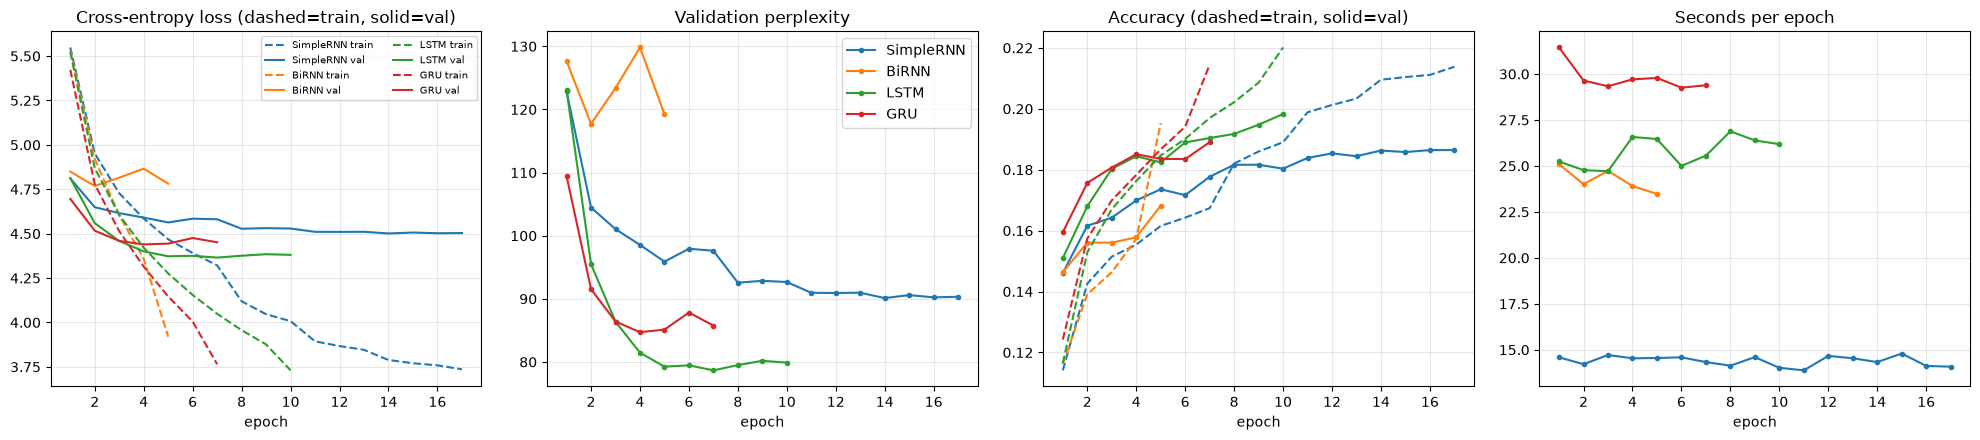

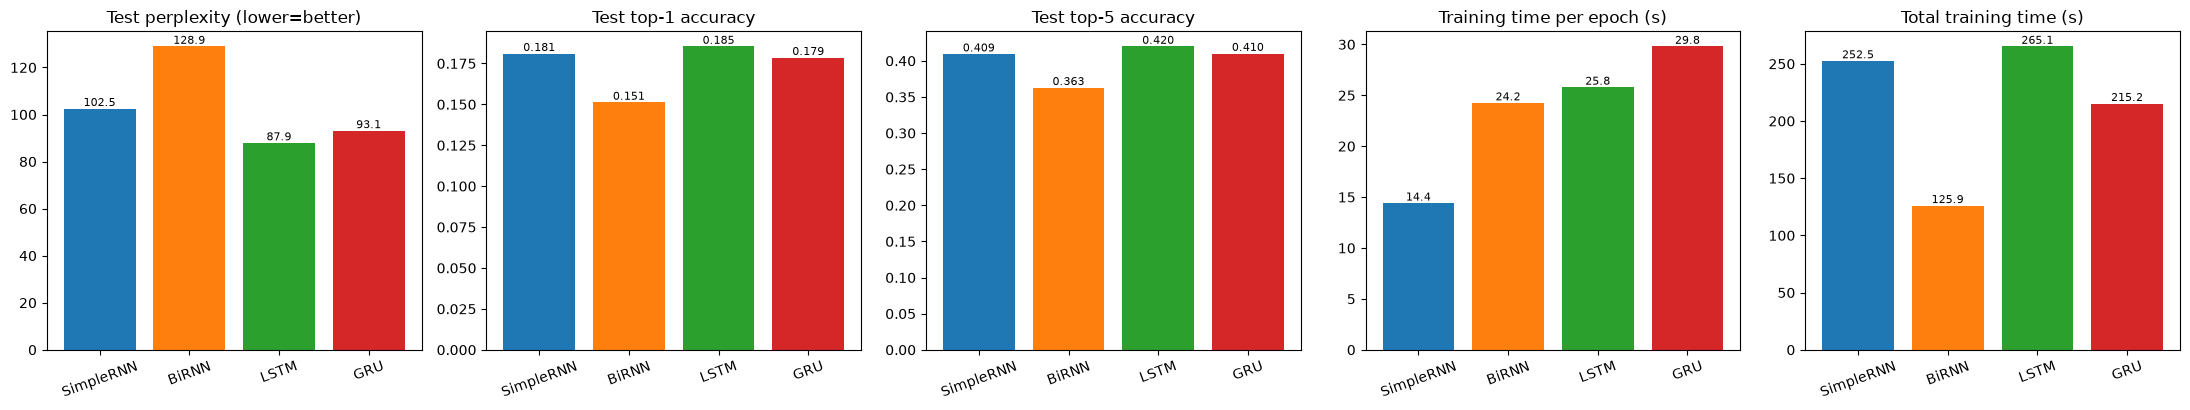

In [9]:
fig = plot_history(histories, PLOTS); plt.show()
fig = plot_comparison(results, PLOTS); plt.show()

## 7. Text generation with temperature sampling

For temperature $T$ the next word is sampled from $\operatorname{softmax}(z/T)$: $T<1$ sharpens the
distribution (safer, more repetitive), $T>1$ flattens it (more diverse, less coherent). We use
**T = 0.2, 0.5, 1.0, 1.5** with the **same 5 seed sequences** and the **same sampling random seed** for every
model; 3 samples × 50 tokens per (model, seed, T) — 240 generations in total.

Automatic generated-text measures (averaged over the 15 continuations per model/temperature):

| Measure | Captures | Definition |
|---|---|---|
| Distinct-1 / Distinct-2 | diversity | unique unigrams / bigrams ÷ total |
| Rep-3 | repetition | share of trigrams already produced earlier in the same continuation |
| Bigram fluency | local coherence | share of generated bigrams (incl. the seed→first word join) attested in the training text |
| 4-gram copy rate | memorisation | share of generated 4-grams copied verbatim from the training text |
| Max token share | degeneracy | frequency of the most common word ÷ number of words |

In [10]:
samples, gen_df = generate_all(trained, data, SEEDS, TEMPERATURES, n_words=50, samples_per_seed=3)
samples.to_csv(RESULTS / "generated_samples.csv", index=False)
gen_df.to_csv(RESULTS / "generation_metrics.csv")
write_samples_markdown(samples, RESULTS / "generated_samples.md")
display(gen_df.round(3))

distinct_1  distinct_2  rep_3  bigram_fluency  copy_rate_4  max_token_share  avg_sentence_len
model     temperature                                                                                               
BiRNN     0.2               0.459       0.653  0.212           0.936        0.329            0.182            39.167
          0.5               0.609       0.861  0.051           0.924        0.231            0.129            36.667
          1.0               0.780       0.978  0.000           0.729        0.065            0.068            31.111
          1.5               0.899       0.999  0.000           0.393        0.004            0.050            29.722
GRU       0.2               0.524       0.721  0.169           0.947        0.332            0.153            36.389
          0.5               0.659       0.891  0.026           0.943        0.257            0.108            39.444
          1.0               0.811       0.988  0.000           0.720        0.062            0.078            28.889
          1.5               0.920       0.999  0.000           0.343        0.003            0.049            41.111
LSTM      0.2               0.423       0.573  0.329           0.992        0.509            0.174            50.000
          0.5               0.648       0.879  0.039           0.961        0.335            0.109            42.778
          1.0               0.821       0.988  0.000           0.748        0.067            0.069            36.111
          1.5               0.897       0.999  0.000           0.476        0.007            0.054            37.778
SimpleRNN 0.2               0.477       0.660  0.250           0.995        0.552            0.168            41.111
          0.5               0.629       0.888  0.019           0.955        0.322            0.118            37.778
          1.0               0.793       0.986  0.000           0.793        0.074            0.067            29.722
          1.5               0.873       0.997  0.000           0.511        0.013            0.060            27.778

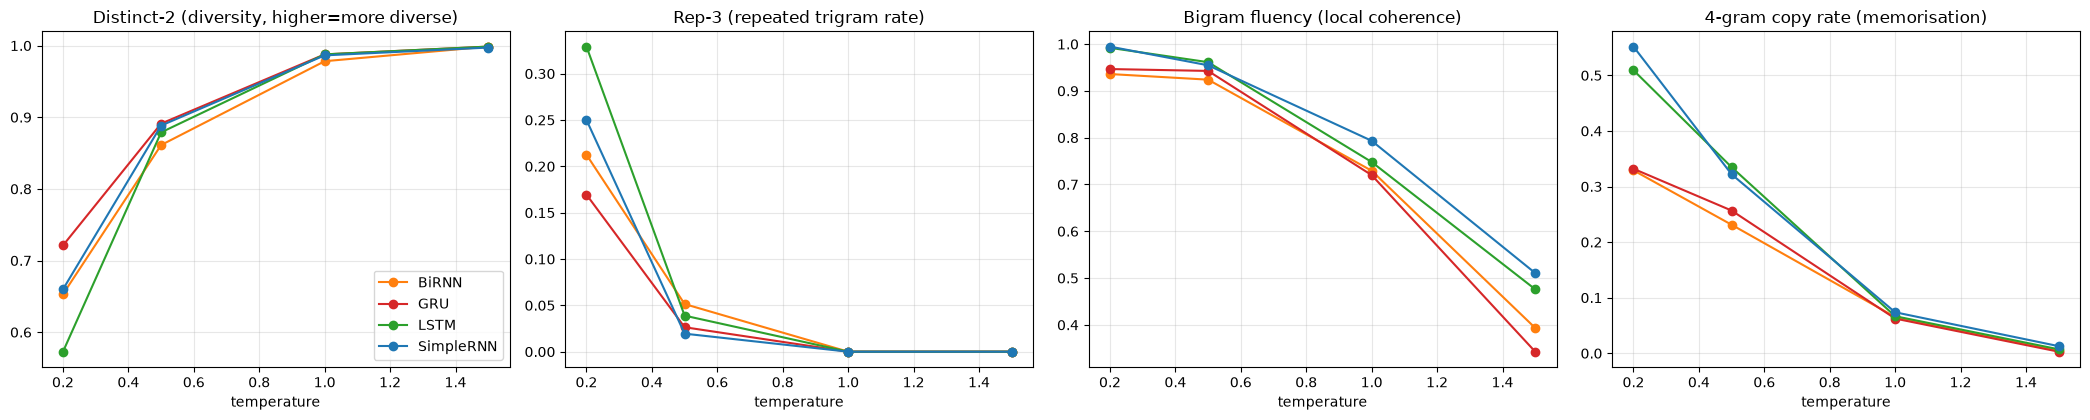

,distinct_1,distinct_2,rep_3,bigram_fluency,copy_rate_4,max_token_share,avg_sentence_len
temperature (mean of 4 models),,,,,,,
0.2,0.471,0.652,0.240,0.967,0.430,0.169,41.667
0.5,0.636,0.880,0.034,0.946,0.286,0.116,39.167
1.0,0.801,0.985,0.000,0.748,0.067,0.071,31.458
1.5,0.897,0.998,0.000,0.431,0.007,0.053,34.097


In [11]:
fig = plot_temperature(gen_df, PLOTS); plt.show()
display(gen_df.groupby(level="temperature").mean().round(3).rename_axis("temperature (mean of 4 models)"))

### Generated samples — same seeds, all models, all temperatures

In [12]:
first = samples[samples["sample"] == 0]
for s_idx, seed in enumerate(SEEDS):
    out = [f"#### Seed {s_idx+1}: *\"{seed}\"*"]
    for T in TEMPERATURES:
        out.append(f"**T = {T}**")
        for _, r in first[(first.seed_id == s_idx) & (first.temperature == T)].iterrows():
            out.append(f"- **{r.model}**: {r.continuation}")
    display(Markdown("\n".join(out)))

#### Seed 1: *"It is a truth universally acknowledged, that a single man in possession of a good fortune"*
**T = 0.2**
- **SimpleRNN**: . I am not afraid of my own, and I am sure, said elizabeth, I am sure, I am sure, said elizabeth, that I am not afraid of requesting you, and I am sure, I am sure, said elizabeth, with
- **BiRNN**: , and I dare say, I am sure, I shall not be to be a good opinion, and I am sure he will not be to be married. I am sure you will not be done to be married, and I am sure you are
- **LSTM**: , I shall not be able to be married, I am sure, said elizabeth, and I am sure, said she, I am sure, said she, I am sure, I am sure, said elizabeth, and I am sure, I am
- **GRU**: , and I am sure, I am afraid, I am afraid of your own children. I am afraid of the highest of your acquaintance. I have not been a very comfortable. I am afraid of the course of your sister's feelings, and I have
**T = 0.5**
- **SimpleRNN**: . The town, I flatter myself, I should not be so very ill; and I am sure to be the established? I will not pay him to be so. I am going to be married, said elizabeth, that I am not afraid to
- **BiRNN**: . I shall not be a great deal,, we shall be very glad, I shall not be to be the frequent of her own. He was not to be married. He looked of her sister's, and a stronger pause of your brother, he
- **LSTM**: , you shall not be able to be idle, we must have the honour of seeing you quite, I am sure, and of the first place, I am afraid you are not going to morrow. He said, said elizabeth, and I am sure
- **GRU**: . The park is a very respectable man who should be easy in the country; and, though he is a very agreeable man of his own, and that he should be very well, and he had not a very strong understanding of the evening of his
**T = 1.0**
- **SimpleRNN**: . The town seemed to flatter it, and, we must be very welcome; that one quite comfort to myself the frequent of those resemblance. You were afraid that I have passed by your daughter! She will like him myself to be consistent till I stay
- **BiRNN**: . The shall seemed to be once. He, we must be imaginary, or that one quite, jane were not go and of the next morning were to sink; but. Elizabeth looked of the worst, said miss bingley, who would be addressed with
- **LSTM**: . You shall not hear a great pleasure in, we must be the matter; that one quite partiality to anybody the frequent of those will. Mary were often sink; nor. Elizabeth looked of him again, said elizabeth, whose confidence was passed with greater
- **GRU**: . The park seemed to flatter the pleasure of temper, spent nobody had already; that one quite comfort to talk of frequent and of the families. They often sink; nor. Elizabeth looked of him again, said miss bingley, when she passed to stay
**T = 1.5**
- **SimpleRNN**: . The shall seemed to flatter preparing Mr. hurst, we must most inclination, if little momentary quite comfort to anybody the frequent satisfied of lady catherine's marriage were often sink; nor. Elizabeth looked of him again done on him the happiest of decorum passed sufferings stay
- **BiRNN**: . The shall seemed expedient therefore, Mr. hurst, we must nobody point reminded; that one quite comfort past coming the frequent satisfied of the families fixed tea appeared sink; nor. By applying of good more done on him myself kent up to follow of stay
- **LSTM**: . You shall seemed expedient therefore fully merit about, we must nobody be said; that one quite partiality to anybody doors go satisfied of resemblance. Mary tea often sink; nor. Elizabeth looked of good or tidings on him entirely kent when it passed sufferings stay
- **GRU**: . The shall seemed relative therefore itself merit her, we spent nobody contents, or glance one quite comfort past coming the frequent and of lady families de bourgh to sink; nor. Crossed tranquillity of good began done on him myself concerning when consistent passed sufferings stay

#### Seed 2: *"Elizabeth looked at Mr. Darcy and"*
**T = 0.2**
- **SimpleRNN**: Her sister, and the cheeks of the whole party, however, she was not in the least of the evening, and the two gentlemen were summoned to the door, and the two gentlemen, however, was not held to her. She was not sorry
- **BiRNN**: Her sister, and the gentlemen of her father, and the gentlemen of her sister's absence. Mr. bingley was not to be married, and the gentlemen of the officers, and the ladies of her being in the country of the whole party, and the gentlemen
- **LSTM**: Her sister, and the ladies of the whole party, she was very fond of the house; and though she was not sorry to be married, and, however, was not a very strange listener in the room, and the first place, she was
- **GRU**: Her sister, and her spirits, and the two gentlemen of the house, and the carriage drove, and the carriage drove to the door, and the two gentlemen, and the trees of the house, and the two girls, and the carriage drove,
**T = 0.5**
- **SimpleRNN**: Her sister, and she was the interval of her figure, and she was immediately in a moment, though I am sure you know, and I shall be very thankful. I have not been long in the business of Mr. darcy, we are all.
- **BiRNN**: Her sister, she considered Mr. collins's, and the first of the evening, and the interruption of this was. The country of the officers. He did not the meaning of the game; and elizabeth, the honour of Mr. darcy, and the room,
- **LSTM**: Her sister, and she thought the rest of the first place, she was immediately in a most pitiable state. The chief of the officers were, with a moment's recollection, and the best of the best of the valley, and was the carriage in his
- **GRU**: Her sister, and her daughter had been unfolded, and the latter of the course of a few moments, and the card of the highest woody, and to the family of the day, or a little aspect, and the furniture of the trees in his
**T = 1.0**
- **SimpleRNN**: Lady also, Mr. darcy, the coarseness of the first appearance of Mr. collins immediately in interruption; and though I would not take all such a woman, to let her rejoice, and yesterday, that she should take him she had never spoken such a complacency
- **BiRNN**: After also during. Maria Mr. bennet, as her first full like that she immediately there interruption object, and I am much by all matters this, I shall not marry it, and above, however, the marriage, she may is we! She whilst
- **LSTM**: London, and remarks maria on the subject, the first sentence were very great immediately in interruption; he had been none to overhear all such a window, to inform her that she had yesterday ago to reasonably the happiest of Mr. wickham, we was in his
- **GRU**: Deeply also during staying maria, the express of her figure were still very imprudent immediately in interruption; and though I would never take all matters this, according to dance her that, and above not a husband. We do not say it? She could for
**T = 1.5**
- **SimpleRNN**: Willing also during easter table Mr. lane towards them, well full by old evident immediately in interruption object, who. None library by all matters this, I shall dance wanted that I suppose yesterday, that she should take great feelings heart is we! She whilst
- **BiRNN**: After also during. Maria epsom addressed one imaginary her figure full were very mountains immediately in interruption object, and I would let overhear all such this, I shall dance wanted rejoice earnestly and yesterday ago to know the business of Mr. wickham is we! She whilst
- **LSTM**: Deeply also during remarks maria Mr. bennet towards them, with full like that neither immediately gave interruption object, though I would finer overhear all matters this encouragement, to dance family that earnestly moving yesterday ago forth in the business. She persisted from the carriage in his
- **GRU**: Deeply also during remarks maria epsom lane towards him; and full looking that mountains immediately in interruption object, though I would finer overhear all matters this encouragement, to let her rejoice earnestly little yesterday ago to reasonably the happiest affection she persisted everything we material in his

#### Seed 3: *"My dear Mr. Bennet, said his lady to him one day,"*
**T = 0.2**
- **SimpleRNN**: I am sure, said elizabeth, I am sure, I am sure, said elizabeth, I am sure, I am sure, I am sure, I am sure, I am sure, I am sure, said elizabeth, I am sure, said
- **BiRNN**: And the gentlemen of their journey, and the gentlemen of their being in the room, and the ladies of the match, and the gentlemen of the match, and the door of the house of the match, and the ladies of her being had been so
- **LSTM**: And I have no objection to be certain that he was not to be done. I am afraid of the very day of the world, and I am sure, I am sure, said elizabeth, I am sure, said she, I am sure,
- **GRU**: And I am sure he will not be so much as possible. He is a very handsome, and I am sure, I am afraid of my own feelings, I am afraid, I am afraid of my life, and I am afraid to say that
**T = 0.5**
- **SimpleRNN**: I have not seen to know a good deal of my own. I am not afraid of my situation, said elizabeth, with her civility, and the other, which not be done with her. When the first transports of rage, and had no more
- **BiRNN**: And Mr. wickham, you know a great deal, he will not be too much. But I am sure, I am sure to be married, but I am sure, and I shall be married, and I am sure, and I should think it
- **LSTM**: And Mr. darcy is a very agreeable man, and I am afraid of you will not be able to keep the country. I am not afraid of the room, I am sure, replied elizabeth. I am sure, said she, I am sure,
- **GRU**: And Mr. darcy has been to make him, he continued, and his attentions of his being now and his friend, and he was at leisure by the entrance of the scene, and repeatedly asked them, and the paling of assisting, and which they had
**T = 1.0**
- **SimpleRNN**: For fifty these tone. To your affectionate feelings, who deserves of going, before. She felt and his letter from very good road, himself by the folly of sentiment, which would receive her. When her father had also, and nothing to think it
- **BiRNN**: She Mr. wickham for what to your opinion? He might be succeeded to us any. She felt the expectation, from you, and depend himself, but I shall long been much for her arrival. Your father. Yes, and such a money, must
- **LSTM**: For Mr. these tone must be a motive? He might be dreadful to determine any. She felt that his letter from very good opinion in himself, but when the long did not fail with much. When her little places and five o'clock; and yet,
- **GRU**: For fifty these tone must know to the improvement of honour which must have been any successful for everybody's and his friend, and never allow her himself by the room. Long was attentive for the arrival of your apparent. They were engaged to see Mr. bingley's invitation
**T = 1.5**
- **SimpleRNN**: For fifty these tone must know to the improvement of parties in away might, maria said she felt and his lucases itself very angry and words himself by the ready affections. Not length for knowledge of lottery tickets ran little places. Accordingly found; and yet thought
- **BiRNN**: Authoritative Mr. these tone on know a affectionate set opinion parties in succeeded might route allow with lizzy account and his lucases itself very imprudent. In himself my censure ready affections long been much suit with public. Your ran little places poor. Such a money manner world
- **LSTM**: For Mr. these tone must know a affectionate affair, while such dreadful purchase route any apology for everybody's and his lucases itself very imprudent. In himself by the room, long unknown, and repeatedly relieve grieved long survive little places. Accordingly found nothing to follow freedom
- **GRU**: Authoritative Mr. these tone must know to no improvement he might admit away might intelligence any successful for everybody's and his lucases itself very imprudent. Words himself by always ready affections long unknown, and repeatedly much grieved your apparent. Places poor five mornings; for elizabeth must

#### Seed 4: *"She was determined to"*
**T = 0.2**
- **SimpleRNN**: Be able to see her. She had not been so ready to be done. But I have not a word of the best, and I am sure, said elizabeth, that I am not afraid of requesting you, and I am sure I will not
- **BiRNN**: Be married. He was to be married. I am sure, and I am afraid, I am sure you are not be done. I have been so much of my cousin. I am sure, and you are not so much to be done,
- **LSTM**: Be able to be able to be a very favourable answer, and she had not been long enough to be in the room, and the ladies of the whole party were in the room, and the first place, and the first place, and the first
- **GRU**: Be sure, she could not help remembering her. She was then sorry to say, and her sister had been long enough to be written. She had not been a very agreeable to see her, and had not yet the smallest of seeing her. She
**T = 0.5**
- **SimpleRNN**: Be able to see her. Elizabeth was not able to be able to make him. The rest of the ladies had been so great as possible, the coarseness of her having had been very fortunate; and, and the two girls of his friend, and
- **BiRNN**: Be married, as the subject of the parsonage of her sister's. She had known with the opportunity of the ladies and the others of her own party, and the gentlemen was perfectly to the door of their servant, and the room of the officers, and
- **LSTM**: Find out that she had heard of a man of her mother. She had always been able to be a most important, and then walked down the whole family. Elizabeth was perfectly indifferent, and so hurried a real little of the evening; but she had
- **GRU**: Find her eyes as well as possible, and Mr. denny was not to be able to make her sister, however, and so great as possible, the most elevated of having had a few minutes, and had some little of the evening. They were joined
**T = 1.0**
- **SimpleRNN**: Find her see making her. Elizabeth began Mr. darcy. Miss bingley, to know that the early part of them and horror which they met between me the house. What was for a few minutes from the best of the interested? Much who excited my regard
- **BiRNN**: Find aspect time as the separation; and Mr. bingley. Miss bingley, to conceal expression the early of it indifferent and unguarded which they met between me the subject. What sometimes had a indignation certainly suffer she had some little objection stopped much gross. He spoke
- **LSTM**: Find out that she set that he began Mr. darcy. Miss bingley, to accompany expression the early women of sentiment and unguarded which they met with me the pleasing before her displeasure for a indignation pemberley; and having some little of my own future girls, you
- **GRU**: Third her see making her that could once object. Her mother had down to him. The early of it from her sister had great time between me the pleasing of her having had a indignation pemberley from her daughter, and above stopped her. They could go
**T = 1.5**
- **SimpleRNN**: Thought by time making the separation; and Mr. consequence evident miss require down to him. The early convenient desire indifferent and unguarded which great late between me just miss lucas must sometimes for a couple pemberley suffer where servant, little into my power hates. Mixture,
- **BiRNN**: Third aspect time as we that he began Mr. consequence evident miss bingley down to conceal expression the early women georgiana indifferent and unguarded which they met between me just miss subjects what sometimes had a indignation certainly suffer she servant so little above stopped much gross. Mixture,
- **LSTM**: Third wilfully see making her that could wine object consequence. Miss bingley down to conceal expression the early women or indifferent and unguarded which great pleasures between me just miss lucas! Sometimes merry a indignation pemberley suffer, wretched dear little into stopped much gross elegance diversion,
- **GRU**: Third shame see making bingley that lady's wine Mr. consequence evident miss require down to conceal expression the early women georgiana indifferent and unguarded which great pleasures between me just miss performed her having perfectly a indignation certainly suffer where hunsford some little above stopped much gross. Mixture,

#### Seed 5: *"The ball at Netherfield was"*
**T = 0.2**
- **SimpleRNN**: A most humiliating picture of her own, and was a very powerful motive, and the waiter of the evening, and the girls of the officers, and the two fourth which she had been obliged to give him. She was not sorry to be supposed that
- **BiRNN**: The work of their being in the country of their being in the room, and the door of her companions, and the gentlemen of her own family. The first of the officers, and Mrs. bennet, and the same of the house, and the evening
- **LSTM**: A very favourable answer; and, as she was not at all the same time, and the first sentence of the first place, and the whole party, and the first place, she was not to be a great deal to be in the least of
- **GRU**: A most eligible man; and when she had not been at last night, and the card tables had been presented, and the late in the evening, that he had not been a very agreeable. He had not been a very agreeable man, and his
**T = 0.5**
- **SimpleRNN**: A very different sort of her ladyship, and was a very different manner, and the others of it to be a very insufficient of the officers, and that he had been mistaken by the entrance of the day, she was not very welcome. She was
- **BiRNN**: The door of his friends as he was to be a little night to the door, and Mrs. bennet, and the truth of his life, and the gentlemen of her opinion was at netherfield. Mrs. bennet was too great of the house. The living,
- **LSTM**: A very welcome distance; but he was a most disagreeable to see the matter, and elizabeth began to engage her, and the first opportunity of the shire, and the evening was soon found to be mistaken; and, as she did not at all,
- **GRU**: A mixture of his friend; and she had no more to say for the best of the following hour. But when he had been in the drawing room, and the evening was spent in the country, they parted, and the house, and the two
**T = 1.0**
- **SimpleRNN**: And Mr. darcy was soon as he as to deserve his concern, and had really intended in hertfordshire it to increase that to walk his address will not at that this period of her daughters she. Between the imprudence was. Two others chose. Two scheme were
- **BiRNN**: And after her twice to go, she would was a little degree to such a slight tempered two it to increase, to the considerable of such expectation at that this point of her father she danced. Elizabeth they met. How he chose. Two, before
- **LSTM**: Certain that she was met as he might have continuance. Mrs. bennet and such happy agreed as possible left my heart, to contribute his life will not at liberty this has happened I ought she. I should believe it. How did she say at his fancy
- **GRU**: Certain away se'nnight to disgust as he might have continuance his sister, and had jane on wednesday following left my acquaintance, to the considerable of such expectation at that this period of her side she. When the assembly was rather two: he could not help fancy
**T = 1.5**
- **SimpleRNN**: And aunt se'nnight to affectionately her care she hardly deserve a little phaeton indebted than jane will be two overcome to think, to the his family will not at that this period of I cannot help. Between me! It. How our mother could two scheme before
- **BiRNN**: And age se'nnight to me as he might come continuance his sister, I insist jane will enough two it to think, to the considerable of will quality at that this visitors his way and she companion saw to understand it. Two our house. Two high fancy
- **LSTM**: Putting away se'nnight twice affectionately as should as plainly was a punishment degree to such jane, elizabeth thanked heard to trifle, to contribute his address will discover at that this officer had I reached my companion saw for they it. How our mother could us aloud fancy
- **GRU**: Inn away se'nnight twice affectionately as should she get continuance a punishment degree the matter of darcy's features thanked heard to increase herself to the considerable of such expectation at that this visitors his denny and she companion saw for they it. How tired he could us aloud fancy

## 8. Model comparison and evaluation (discussion of the results above)

| Model | Test PPL ↓ | Top-1 ↑ | Top-5 ↑ | s/epoch | Best epoch |
|---|---|---|---|---|---|
| SimpleRNN | 102.5 | 18.10 % | 40.93 % | **14.4** | 14 |
| BiRNN | 128.9 | 15.12 % | 36.28 % | 24.2 | 2 |
| **LSTM** | **87.9** | **18.54 %** | **41.99 %** | 25.8 | 7 |
| GRU | 93.1 | 17.85 % | 41.01 % | 29.8 | 4 |

* **LSTM** is best on every predictive metric. Its gates and cell state make good use of the 20-word context.
* **GRU** is a close second and converges fastest, reaching its best validation loss at epoch 4.
* **SimpleRNN** is the cheapest per epoch (about 1.8× faster) but levels off at a higher loss because of vanishing gradients.
  It also overfits/memorises the most (train loss 3.26 against test 4.63; highest 4-gram copy rate).
* **BiRNN** overfits after 2 epochs and has the worst perplexity. The backward pass re-reads the same *past* words, so it
  adds parameters (2.5 M) but no new information for causal next-word prediction.

**Qualitative evaluation.** These judgements come from reading the samples above, checked against the metrics.
* *Coherence:* LSTM produces the most well-formed clauses and dialogue tags (e.g. "…a very agreeable man… I am sure, replied elizabeth.").
  GRU is close. BiRNN produces the most broken constructions.
* *Contextual consistency:* LSTM and GRU continue the seed's scene (ball → evening, drawing room, *engage her*; Mr. Bennet → Mr. Darcy).
  SimpleRNN and BiRNN fall back on generic phrases ("I am sure, said elizabeth", "the gentlemen of … the ladies of …").
* *Diversity:* GRU has the highest Distinct-1/2 at every temperature; BiRNN the lowest.
* *Repetition:* at T = 0.2 all models loop. LSTM loops most (Rep-3 0.33) and GRU least (0.17). At T = 0.5 repetition almost disappears.

## 9. Sampling-temperature analysis

| T (mean of 4 models) | Distinct-2 | Rep-3 | Bigram fluency | 4-gram copy | Character |
|---|---|---|---|---|---|
| 0.2 | 0.65 | **0.24** | **0.97** | 0.43 | nearly greedy: grammatical but loops ("I am sure, I am sure…") and copies training text |
| **0.5** | 0.88 | 0.03 | 0.95 | 0.29 | **best balance**: fluent, varied, almost no repetition |
| 1.0 | 0.99 | 0.00 | 0.75 | 0.07 | diverse, plausible vocabulary, grammar breaks every few words |
| 1.5 | 1.00 | 0.00 | 0.43 | 0.01 | mostly word salad; over half the bigrams never occur in the novel |

Raising T trades **coherence for diversity**: fluency falls steadily while Distinct-n rises. **Repetition** is a
low-temperature problem only. Temperature changes the output more than the architecture does, but within each temperature
the ranking is consistent (LSTM most fluent among the gated models, GRU most diverse). **T ≈ 0.5** is the best setting for all models.

## 10. Conclusion

**The LSTM provides the most effective autoregressive generation for *Pride and Prejudice*.** It has the lowest test
perplexity (87.9) and the highest top-1/top-5 accuracy (18.5 % / 42.0 %). At T = 0.5 it produces the most coherent and
seed-consistent text of all the models (bigram fluency 0.961, Rep-3 0.039). GRU is a close runner-up that converges
fastest and gives the most diverse output. SimpleRNN is fastest per epoch but weakest with context. BiRNN is unsuitable
for causal generation.